# Using the Group Stretch proposal

In this tutorial, we will use the Group Stretch proposal in a simple example. The Group Stretch is very useful when our nested model is ... 

### 0. Necessary imports

In [1]:
import numpy as np
import pandas as pd
from chainconsumer import ChainConsumer, Chain, PlotConfig, Truth
import matplotlib.pyplot as plt
import matplotlib as mpl
def update_mpl(mpl):
    rcparams = {}
    rcparams["axes.linewidth"] = 0.5
    rcparams["font.family"] = "serif"
    rcparams["font.size"] = 18
    rcparams["legend.fontsize"] = 14
    rcparams["mathtext.fontset"] = "stix"
    mpl.rcParams.update(rcparams) # update plot parameters
    useserif=True
    plottempsetc=False
    mpl.rcParams["text.usetex"]=True
    return mpl
mpl = update_mpl(mpl)
from matplotlib import cm

from eryn.state import State, BranchSupplemental
from eryn.ensemble import EnsembleSampler
from eryn.prior import uniform_dist
from eryn.moves import GaussianMove, GroupStretchMove, StretchMove, CombineMove
from eryn.backends import HDFBackend

Define the setup of the simulation. Choose the number of pulses to inject in the data (any between 1 and 30 should work fine for this example), the number of MCMC steps, and the number of temperatures and walkers.

In [2]:
nsteps = 2000  # total mcmc steps
burnin = 1000  # burn in period steps
ntemps = 5     # number of temperatures
nwalkers = 20  # mumber of walkers
npulses = 10   # number of pulses to inject

np.random.seed(123456) # Set the random seed

### 1. Generate the data-set

In [3]:
# Set number of samples and the x-axis vector
num     = 100
lowlim  = - 0.1 * num # put all injections well inside the measurement (avoid edges)
highlim = 0.1 * num
dt      = (highlim - lowlim)/num 
x, y    = np.mgrid[lowlim:highlim:dt, lowlim:highlim:dt]
Amp     = np.random.uniform(.8, 1.2, size=(npulses))
spread  = .2
sigma   = spread * np.diag(np.ones(2))
edges   = 2

# Set the injection parameters
inj_coordinates = np.random.uniform(lowlim+edges, highlim-edges, size=(npulses, 2))

gauss_inj_params = [ [AA, xy[0], xy[1]] for AA, xy in zip(Amp, inj_coordinates)]

print(" * Parameters injected: \n\n", np.matrix(gauss_inj_params), "\n\n")

sigma_det = np.linalg.det(sigma)
sigma_inv = np.linalg.inv(sigma)
norm      = np.sqrt((2*np.pi)**2 * sigma_det)

sgm1, sgm2 = sigma[0,0], sigma[1,1]

def gaussian_flat(x, y, a, b, c):
    """
        Gaussian (2D) flat. Yields the flattened vector of 
        distributions for given parameters input:
        x, y - The coordinates
        a, b, c, the amplitude, and the position of each pulse.
    """
    pos = np.empty(x.shape + (2,))
    pos[:, :, 0] = x 
    pos[:, :, 1] = y
    mu = [b, c]
    # This einsum call calculates (x-mu)T.Sigma-1.(x-mu) in a 
    # vectorized way across all the input variables.
    fac = np.einsum("...k,kl,...l->...", pos-mu, sigma_inv, pos-mu)
    return a * np.exp(- fac / 2) / norm

sigma_noise = [[0.2]]
noise = sigma_noise[0][0] * np.random.randn( num, num )

# Generate the data-set
injection = np.zeros( (num, num) )
for params in gauss_inj_params:
    injection += gaussian_flat(x, y, *params)
data = injection + noise

params = np.array(gauss_inj_params)
params[:,0] = params[:,0]

 * Parameters injected: 

 [[ 0.85078793 -2.0318044  -0.83205081]
 [ 1.18668714 -5.92894912  5.75805931]
 [ 0.9041904   5.12621381 -2.36714337]
 [ 1.15889461 -4.33780313  4.42854001]
 [ 0.95069989  1.51653743 -5.79914309]
 [ 0.9344887   5.6463965  -4.23188034]
 [ 0.98055059 -5.66036428  1.43790037]
 [ 1.13610203  1.1841884  -7.0196806 ]
 [ 0.84924086  1.44681605 -4.07440289]
 [ 1.01721048 -2.552881    7.75565983]] 




Make a plot of the generated data:

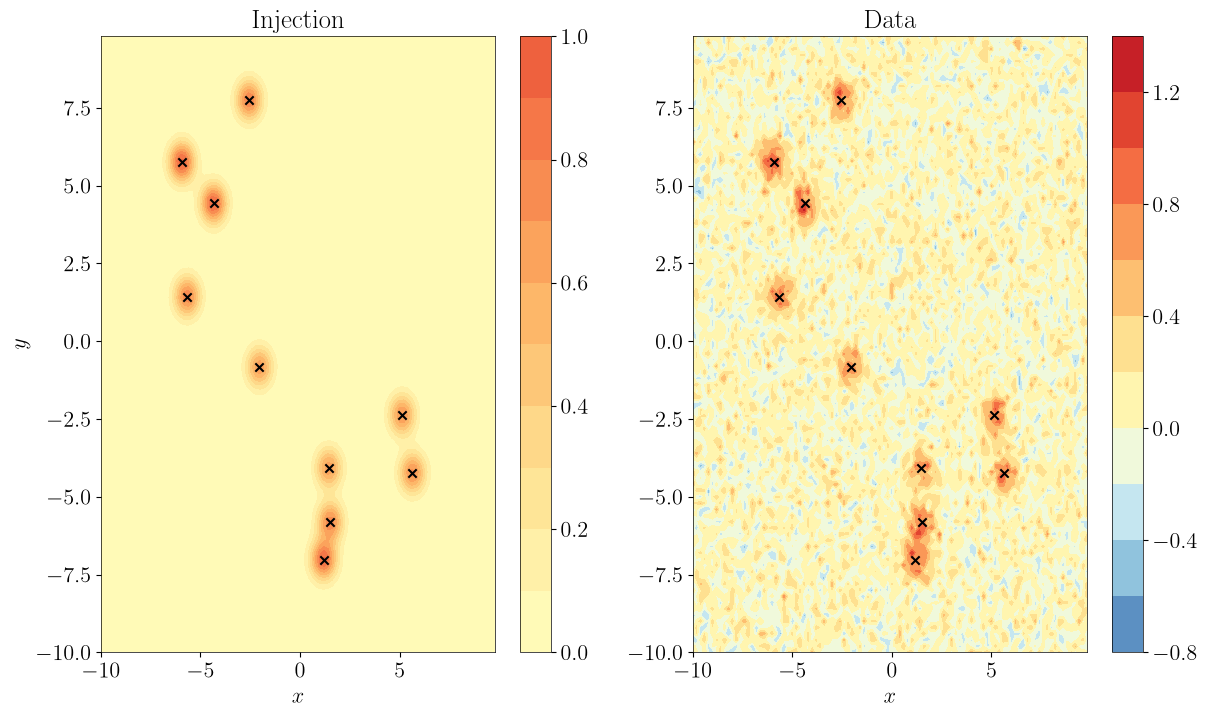

In [4]:
import matplotlib.colors as colors
vmin = - 1.0 
vmax = 1.5
cnorm = colors.TwoSlopeNorm(vmin=vmin, vcenter=0, vmax=vmax)

fig = plt.figure(figsize=(14,8))
plt.subplot(121)
cf = plt.contourf(x, y, injection, 10, norm=cnorm, cmap=cm.RdYlBu_r)
plt.scatter(params[:,1], params[:,2], marker="x", color="k")
plt.colorbar(cf)
plt.xlabel(r"$x$")
plt.ylabel(r"$y$")
plt.subplot(122)
cf = plt.contourf(x, y, data, 10, norm=cnorm, cmap=cm.RdYlBu_r)
plt.scatter(params[:,1], params[:,2], marker="x", color="k")
plt.xlabel(r"$x$")
plt.colorbar(cf)
ax_list = fig.axes
ax_list[0].title.set_text("Injection")
ax_list[2].title.set_text("Data")
plt.show()

### 2. Define the necessary functions

In [5]:
def gaussian(X, Y, a, b, c):
    x = X[:,0]
    y = Y[0,:]
    A = np.exp(-((x[:, None] - b) ** 2) / (2 * sgm1))
    B = np.exp(-((y[:, None] - c) ** 2) / (2 * sgm2)) 
    C =  A*B[:,None,:] # (np.enpand_dims(A,axis=0) * np.enpand_dims(np.transpose(B),axis=2))
    return np.transpose( a * C / norm , axes=(1,0,2))

def log_prob_fn(x, groups, X, Y, data, inds=None, fill_inds=[], fill_values=None):

    x1, x2 = x
    group1, group2 = groups
    a = np.array(x1[:, 0])
    b = np.array(x1[:, 1])
    c = np.array(x1[:, 2])
    n = num * num

    gauss_out  = gaussian(X, Y, a, b, c)
    num_groups = int(group1.max() + 1)
    template   = np.zeros((num_groups, num, num))
    
    for i in range(num_groups):
        inds1 = np.where(group1 == i)
        given_signal = gauss_out[:,:,inds1].squeeze().sum(axis=-1)
        template[i] += given_signal

    sig = np.atleast_2d( np.array(x2) )[:,0]
    llh = - 0.5 * ( np.sum(((template - data)) ** 2, axis=(1, 2)) )
    llh *= 1/sig**2
    llh += - n*np.log(sig) - .5 * n * np.log(2.*np.pi)
    return llh

### 3. Set-up the sampler 
For details please check the previous tutorials. This type data-set has been used in previous examples.

In [6]:
branch_names = ["pulse", "noise"] 
nleaves_max = {"pulse": 2 * (npulses),  # Maximum number of components for each model type.
               "noise": 1}              # Noise is 1, because we don"t want to use RJ MCMC on it
nleaves_min = {"pulse": 1, 
               "noise": 1}
ndims = {"pulse": 3,  # The dimensions of the two models we sample for here (# of parameter for each pulse, and # of parameters for the noise)
         "noise": 1}

priors = {
    "pulse": {
        0: uniform_dist(0.5, 2.),
        1: uniform_dist(lowlim, highlim),
        2: uniform_dist(lowlim, highlim),
    },
    "noise": {
        0: uniform_dist(0.000001, 2.),
    }
}

coords = {
    name: np.zeros((ntemps, nwalkers, nleaves_max[name], ndims[name])) for name in branch_names
}

sig1 = 0.0000001
inds = {}
for name in branch_names:
    nleaf, ndim = nleaves_max[name], ndims[name] 
    for nn in range(nleaf):
        if name == "pulse":
            if nn >= len(gauss_inj_params):
                kk = np.random.randint(low=0, high=npulses)
            else: 
                kk = nn
            coords[name][:, :, kk] = np.random.multivariate_normal(gauss_inj_params[kk], np.diag(np.ones(3) * sig1), size=(ntemps, nwalkers))
        else:
            coords[name][:, :, nn] = np.random.multivariate_normal(sigma_noise[nn], np.diag(np.ones(1) * sig1), size=(ntemps, nwalkers))  

    inds[name] = np.random.randint(low=0, high=1, size=(ntemps, nwalkers, nleaf), dtype=bool) 

inds["pulse"][:, :, :3] = True

for name, inds_temp in inds.items():
    inds_fix = np.where(np.sum(inds_temp, axis=-1) == 0)

    for ind1, ind2 in zip(inds_fix[0], inds_fix[1]):
        inds_temp[ind1, ind2, 0] = True

groups = {
    name: np.arange(coords[name].shape[0] * coords[name].shape[1]).reshape(
        coords[name].shape[:2]
    )[:, :, None]
    for name in coords
}

groups = {
    name: np.repeat(groups[name], coords[name].shape[2], axis=-1) for name in groups
}

coords_in = {name: coords[name][inds[name]] for name in coords}
groups_in = {name: groups[name][inds[name]] for name in groups}

# We compute the initial likelihood value at the injected coordinates:
log_prob = log_prob_fn(
    [coords_in["pulse"], coords_in["noise"]],
    [groups_in["pulse"], groups_in["noise"]],
    x,
    y,
    data,
    fill_inds=[],
    fill_values=None,
)

log_prob = log_prob.reshape(ntemps, nwalkers)
betas = np.linspace(1.0, 0.0, ntemps)

### 4. Define the Group Move here

The group stretch proposes $x' = c + z\,(x - c)$ for each pulse, where the friend $c$ is drawn from a group of pulses that are close to it. We group the pulses by their position: the friends of a pulse are the `nfriends` pulses of the cold chain nearest to it in $(x, y)$. With `nfriends = nwalkers` and one copy of each pulse per walker, the friends of a pulse are essentially all the cold-chain copies of that same pulse, as in the galactic-binary moves.

The friends are chosen in `setup_friends`, which runs every `n_iter_update` iterations, and are stored per leaf in a branch supplemental, so that they move with the leaf when walkers are swapped between temperatures. `fix_friends` assigns friends to the pulses added by the reversible-jump move. The stretch acceptance assumes that the friend choice does not depend on the current position of the pulse, so the friends must not be recomputed at every step (see the `GroupMove` docstring and the `groupstretch_friends_bias` notebook). Updating them every `n_iter_update` iterations makes the sampler adaptive; we use `freeze_after=burnin` to stop the updates at the end of burn-in, so that the move is exact while the samples are stored.


In [7]:
class MyGroupMove(GroupStretchMove):
    """Group stretch for the pulses.

    The friends of a pulse are the ``nfriends`` pulses of the cold chain that are nearest
    to it in (x, y). They are stored per leaf in a branch supplemental, so they move with
    the leaf when walkers are swapped between temperatures.
    """

    def nearest(self, coords):
        """Indices in the pool of the nfriends pulses nearest to each pulse in coords"""
        dist = np.abs(coords[:, None, 1:] - self.pool[None, :, 1:]).sum(axis=-1)
        return np.argsort(dist, axis=1)[:, : self.nfriends]

    def setup_friends(self, branches):
        branch = branches["pulse"]
        self.pool = branch.coords[0][branch.inds[0]].copy()  # pulses of the cold chain
        inds_closest = -np.ones(branch.inds.shape + (self.nfriends,), dtype=int)
        inds_closest[branch.inds] = self.nearest(branch.coords[branch.inds])
        branch.branch_supplemental[:] = {"inds_closest": inds_closest}

    def fix_friends(self, branches):
        branch = branches["pulse"]
        inds_closest = branch.branch_supplemental[:]["inds_closest"]
        inds_closest[~branch.inds] = -1                      # pulses removed by RJ
        new = branch.inds & (inds_closest[..., 0] == -1)     # pulses added by RJ
        if np.any(new):
            inds_closest[new] = self.nearest(branch.coords[new])
        branch.branch_supplemental[:] = {"inds_closest": inds_closest}

    def find_friends(self, name, s, s_inds=None, branch_supps=None):
        inds_closest = branch_supps[name][s_inds]["inds_closest"]
        pick = np.random.randint(self.nfriends, size=len(inds_closest))
        friends = np.zeros_like(s)
        friends[s_inds] = self.pool[inds_closest[np.arange(len(inds_closest)), pick]]
        return friends


In [8]:
alpha = 2 # Configuration parameter for the stretch move

using_group_moves = CombineMove([
    MyGroupMove(nfriends=nwalkers, freeze_after=burnin, gibbs_sampling_setup="pulse", a=alpha),
    StretchMove(gibbs_sampling_setup="noise", live_dangerously=True)
])


### 5. Run Eryn and search for pulses in the data

For the first case, using the Group Stretch move for the pulses and the Stretch move for the noise

In [9]:
ensemble_group = EnsembleSampler(
    nwalkers,
    ndims,  # assumes ndim_max
    log_prob_fn,
    priors,
    args=[x, y, data],
    tempering_kwargs=dict(betas=betas),
    nbranches=len(branch_names),
    branch_names=branch_names,
    nleaves_max=nleaves_max,
    nleaves_min=nleaves_min,
    provide_groups=True,
    plot_iterations=-1,
    vectorize=True,
    moves=using_group_moves,
    rj_moves=True,
)
    
# the friends of each pulse are stored in a branch supplemental
branch_supps = {"pulse": BranchSupplemental({"inds_closest": np.zeros(inds["pulse"].shape + (nwalkers,), dtype=int)},
                                            base_shape=inds["pulse"].shape),
                "noise": None}
state = State(coords, log_like=log_prob, betas=betas, blobs=None, inds=inds, branch_supplemental=branch_supps)

ensemble_group.run_mcmc(state, nsteps, burn=burnin, progress=True, thin_by=1)

  0%|          | 0/1000 [00:00<?, ?it/s]

  0%|          | 1/1000 [00:00<07:03,  2.36it/s]

  0%|          | 2/1000 [00:00<07:40,  2.17it/s]

  0%|          | 3/1000 [00:01<07:49,  2.12it/s]

  0%|          | 4/1000 [00:01<06:57,  2.39it/s]

...

100%|█████████▉| 1997/2000 [27:19<00:00,  6.46it/s]

100%|█████████▉| 1998/2000 [27:19<00:00,  6.58it/s]

100%|█████████▉| 1999/2000 [27:19<00:00,  6.71it/s]

100%|██████████| 2000/2000 [27:19<00:00,  6.83it/s]

100%|██████████| 2000/2000 [27:19<00:00,  1.22it/s]

### 6. Do one with simple Gaussian proposals for the pulses

For comparison, the pulses are now sampled with a Gaussian proposal, while the noise keeps the same stretch move, so the two runs differ only in the proposal for the pulses. The step sizes are about 0.4 times the posterior widths of $A$, $x$ and $y$, since all pulses are moved together.


In [10]:
cov = {"pulse": np.diag([0.03, 0.02, 0.02])**2}  # about 0.4 of the posterior widths of A, x, y
using_gauss_moves = CombineMove([
    GaussianMove(cov, gibbs_sampling_setup="pulse"),
    StretchMove(gibbs_sampling_setup="noise", live_dangerously=True)
])

ensemble_gauss = EnsembleSampler(
    nwalkers,
    ndims,  # assumes ndim_max
    log_prob_fn,
    priors,
    args=[x, y, data],
    tempering_kwargs=dict(betas=betas),
    nbranches=len(branch_names),
    branch_names=branch_names,
    nleaves_max=nleaves_max,
    nleaves_min=nleaves_min,
    provide_groups=True,
    plot_iterations=-1,
    vectorize=True,
    moves=using_gauss_moves,
    rj_moves=True,
)
    
ensemble_gauss.run_mcmc(state, nsteps, burn=burnin, progress=True, thin_by=1)

  0%|          | 0/1000 [00:00<?, ?it/s]

  0%|          | 3/1000 [00:00<00:47, 21.18it/s]

  1%|          | 6/1000 [00:00<00:47, 20.93it/s]

  1%|          | 9/1000 [00:00<00:52, 18.84it/s]

  1%|          | 11/1000 [00:00<00:53, 18.39it/s]

...

100%|█████████▉| 1997/2000 [05:46<00:00,  7.24it/s]

100%|█████████▉| 1998/2000 [05:46<00:00,  7.25it/s]

100%|█████████▉| 1999/2000 [05:46<00:00,  7.29it/s]

100%|██████████| 2000/2000 [05:46<00:00,  7.30it/s]

100%|██████████| 2000/2000 [05:46<00:00,  5.77it/s]

### 8. Plot the results

In [11]:
def get_clean_chain(coords, ndim, temp=0):
    """Simple utility function to extract the squeezed chains for all the parameters
    """
    naninds    = np.logical_not(np.isnan(coords[:, temp, :, :, 0].flatten()))
    samples_in = np.zeros((coords[:, temp, :, :, 0].flatten()[naninds].shape[0], ndim))  # init the chains to plot
    # get the samples to plot
    for d in range(ndim):
        givenparam = coords[:, temp, :, :, d].flatten()
        samples_in[:, d] = givenparam[
            np.logical_not(np.isnan(givenparam))
        ]  # Discard the NaNs, each time they change the shape of the samples_in
    return samples_in

samples_group = get_clean_chain(ensemble_group.backend.get_chain(thin=1)["pulse"], ndims["pulse"])
samples_gauss = get_clean_chain(ensemble_gauss.backend.get_chain(thin=1)["pulse"], ndims["pulse"])

In [12]:
# Choose some nice colours:
gauss_col = "#6082B6"
group_col = "#FFAA33"

Do the triangle plot for the parameters of the pulses (for all pulses found in the data)

Parameter $x$ in chain Proposal: Gaussian is not constrained


Parameter $x$ in chain Proposal: Group Stretch is not constrained


Parameter $y$ in chain Proposal: Gaussian is not constrained


Parameter $y$ in chain Proposal: Group Stretch is not constrained


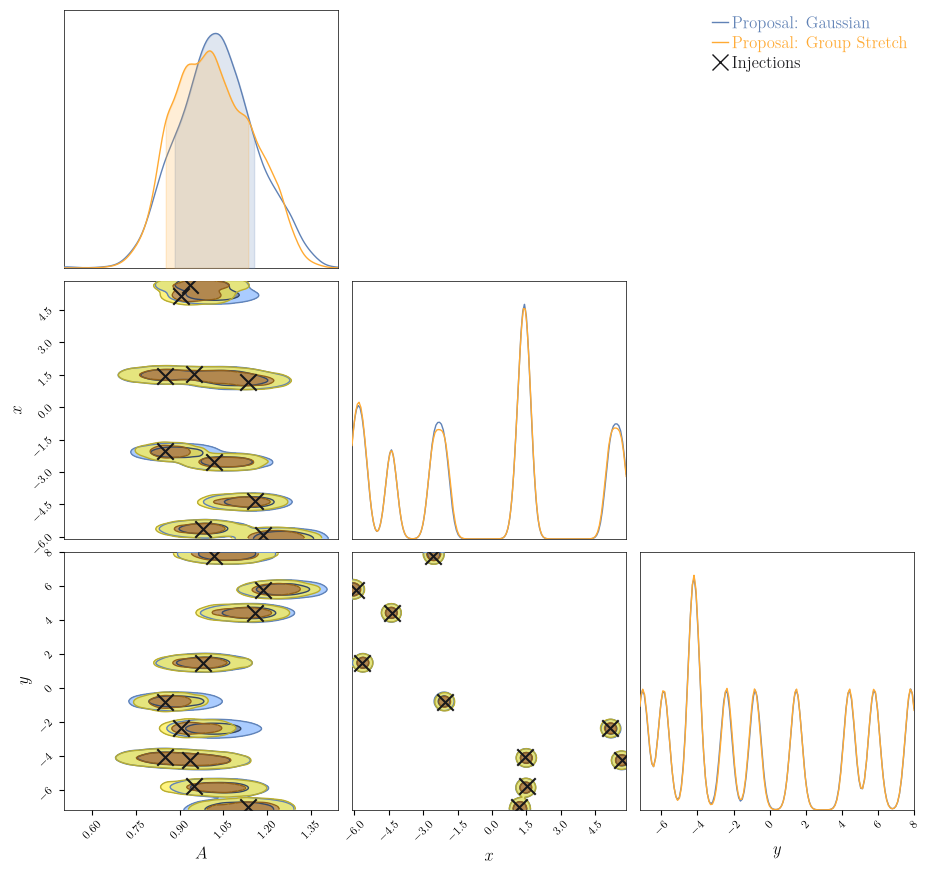

In [13]:
pulse_parameters = ["$A$", r"$x$", r"$y$"]
noise_parameters = [r"$\sigma_\mathrm{noise}$"]

c = ChainConsumer()
c.add_chain(Chain(samples=pd.DataFrame(samples_gauss, columns=pulse_parameters), name="Proposal: Gaussian", color=gauss_col, bar_shade=True))
c.add_chain(Chain(samples=pd.DataFrame(samples_group, columns=pulse_parameters), name="Proposal: Group Stretch", color=group_col, bar_shade=True))

for ii in range(npulses):
    c.add_marker(location=dict(zip(pulse_parameters, gauss_inj_params[ii])), name="Injections" if ii == 0 else f"injection {ii}",
                 color="k", marker_style="x", marker_size=140, show_label_in_legend=(ii == 0))

c.set_plot_config(PlotConfig(tick_font_size=8, label_font_size=12, max_ticks=8, usetex=True, serif=True))
fig = c.plotter.plot(figsize=(10, 10))


The corner plot above mixes all pulses. To compare the two proposals pulse by pulse, we take the cold-chain samples with exactly `npulses` pulses, assign each pulse to the nearest injection, and compare the posterior width of each parameter with the Fisher-matrix estimate at the injection.


In [14]:
def per_pulse_std(backend):
    """Posterior width of A, x, y for each injected pulse, from the cold-chain samples with npulses pulses"""
    coords, inds = backend.get_chain()["pulse"][:, 0], backend.get_value("inds")["pulse"][:, 0]
    keep = inds.sum(axis=-1) == npulses
    pts = coords[keep][inds[keep]].reshape(-1, npulses, 3)
    label = np.linalg.norm(pts[:, :, None, 1:] - params[None, None, :, 1:], axis=-1).argmin(axis=-1)
    one_each = np.all(np.sort(label, axis=-1) == np.arange(npulses), axis=-1)  # each injection found once
    pts, label = pts[one_each], label[one_each]
    return np.array([pts[label == j].std(axis=0) for j in range(npulses)])

# Fisher matrix of the pulse parameters, for white noise of standard deviation sigma_noise
def pulse_derivatives(A, b, c):
    g = gaussian_flat(x, y, 1.0, b, c)
    return [g, A * g * (x - b) / sgm1, A * g * (y - c) / sgm2]

D = np.array([d.ravel() for p in params for d in pulse_derivatives(*p)])
fisher_std = np.sqrt(np.diag(np.linalg.inv(D @ D.T / sigma_noise[0][0]**2))).reshape(npulses, 3)

std_group, std_gauss = per_pulse_std(ensemble_group.backend), per_pulse_std(ensemble_gauss.backend)
print("posterior width / Fisher width, median over the pulses (A, x, y)")
print("  Group stretch:", np.round(np.median(std_group / fisher_std, axis=0), 2))
print("  Gaussian:     ", np.round(np.median(std_gauss / fisher_std, axis=0), 2))


posterior width / Fisher width, median over the pulses (A, x, y)
  Group stretch: [1.08 1.05 1.06]
  Gaussian:      [1.04 1.02 1.  ]


Plot the posteriors for the noise parameters as well.

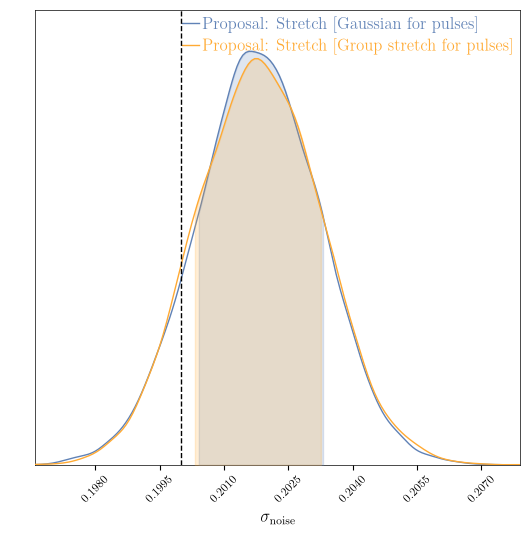

In [15]:
c = ChainConsumer()

samples_noise_group = get_clean_chain(ensemble_group.backend.get_chain(thin=1)["noise"], ndims["noise"])
samples_noise_gauss = get_clean_chain(ensemble_gauss.backend.get_chain(thin=1)["noise"], ndims["noise"])

c.add_chain(Chain(samples=pd.DataFrame(samples_noise_gauss, columns=noise_parameters), name="Proposal: Stretch [Gaussian for pulses]", color=gauss_col, bar_shade=True))
c.add_chain(Chain(samples=pd.DataFrame(samples_noise_group, columns=noise_parameters), name="Proposal: Stretch [Group stretch for pulses]", color=group_col, bar_shade=True))
c.add_truth(Truth(location={noise_parameters[0]: sigma_noise[0][0]}))

c.set_plot_config(PlotConfig(tick_font_size=8, label_font_size=12, max_ticks=8, usetex=True, serif=True))
fig = c.plotter.plot(figsize=(6, 6))


In [16]:
def get_clean_k_chains(backend, temp=0):
    """ A simple function to get the chains of model order k
    Args:
        backend: Eryn backend
    Returns:
        k_chain: the chains of the k model order
    """
    inds = backend.get_value("inds")  # Get the leaves out
    branches = {name: np.sum(inds[name], axis=-1, dtype=int) for name in inds}
    for (branch) in (branches):  # Get the total number of components/branches per temperature
        if branch == list(branches.keys())[0]:
            k_chain = branches[branch][:, temp].flatten()
        else:
            k_chain += branches[branch][:, temp].flatten()
    return k_chain

Plot the posterior on the model order, or in other words, the uncertainty on the model count.

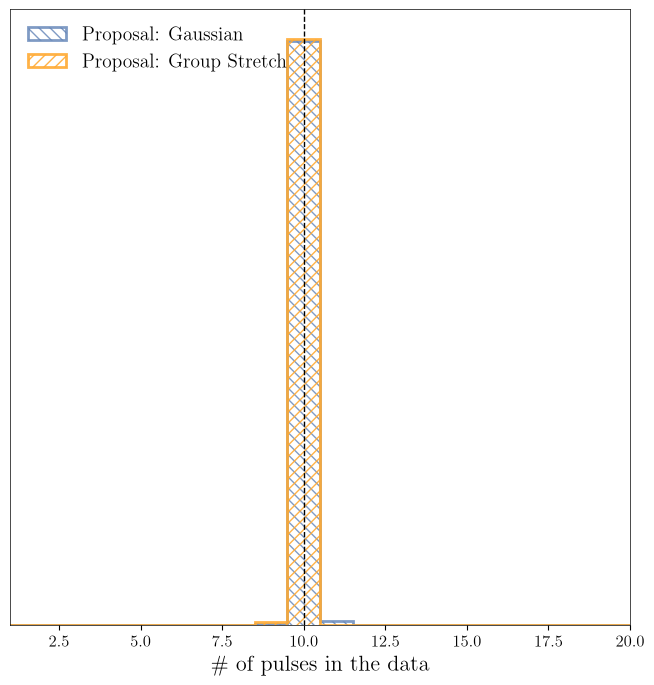

In [17]:
k_chain_group = get_clean_k_chains(ensemble_group.backend)
k_chain_gauss = get_clean_k_chains(ensemble_gauss.backend)

bns = (np.arange(1, nleaves_max["pulse"] + 2) - 0.5)  # Get maximum allowed number of leaves for the given branch

fig = plt.figure(figsize=(8, 8))

plt.hist(
        k_chain_gauss-1,
        bins=bns,
        color=gauss_col,
        alpha=0.8,
        lw=2,
        histtype="step",
        density=True,
        hatch="\\\\\\",
        label="Proposal: Gaussian",
        )

plt.hist(
        k_chain_group-1,
        bins=bns,
        color=group_col,
        alpha=0.9,
        lw=2,
        histtype="step",
        density=True,
        hatch=r"///",
        label="Proposal: Group Stretch",
        )

plt.axvline(x=int(npulses), linestyle="--", lw=1, color="k")

plt.legend(loc="upper left", frameon=False)
plt.xticks(fontsize=12)
plt.yticks([])
plt.xlim(1, nleaves_max["pulse"])
plt.xlabel(r"$\#$ of pulses in the data")
plt.show()

## $fin$